<a href="https://colab.research.google.com/github/uztuis/joe/blob/main/Lab_Hierarchical_Clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CSE206 Fundamental of Machine Learning
## Hierarchical Clustering: Agglomerative and Divisive Approaches, Linkage Criteria and Dendrograms

**Duration:** 2 hours

| Part | Time | What happens |
|---|---|---|
| Session 1 | 60 min | Guided walkthrough with explanations and examples |
| Session 2 | 60 min | Graded exercises (3 exercises, 100 marks, about 30 minutes of work) |

**By the end of this lab you should be able to:**
1. Explain what hierarchical clustering is and how it differs from K-Means.
2. Describe the two approaches: agglomerative (bottom-up) and divisive (top-down).
3. Explain the four common linkage criteria: single, complete, average and Ward.
4. Draw and read a dendrogram, and cut it to get clusters.
5. Evaluate clustering results using the silhouette score.

---
# SESSION 1: Guided Walkthrough

## 1. What is hierarchical clustering?

**Clustering** means putting similar data points into groups (clusters) **without** being told the correct answer. It is an *unsupervised* learning method.

In K-Means you must choose the number of clusters K **before** you start. Hierarchical clustering works differently: it builds a **tree of clusters** (a hierarchy). You can look at the tree and then decide how many clusters you want.

There are two ways to build the tree:

| Approach | Direction | How it works |
|---|---|---|
| **Agglomerative** | Bottom-up | Start with every point as its own cluster. Repeatedly **merge** the two closest clusters until only one cluster is left. |
| **Divisive** | Top-down | Start with all points in one big cluster. Repeatedly **split** a cluster into two until you have the number of clusters you want (or every point is alone). |

Agglomerative is much more common and is the one you will find in most libraries. We will study it first, then look at divisive.

The tree is drawn as a diagram called a **dendrogram** (from the Greek word *dendron* = tree).

## 2. Import the libraries

- `numpy` and `pandas`: work with numbers and tables
- `matplotlib`: draw plots
- `scipy.cluster.hierarchy`: build the tree and draw dendrograms
- `sklearn`: ready-made clustering models, datasets and evaluation scores

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import pdist, squareform

from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.datasets import make_blobs, make_moons
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

print("Libraries loaded")

Libraries loaded


## 3. A tiny example with 6 points

We start with only 6 points so we can follow every step by eye. Each point has two features (x and y) and a name from A to F.

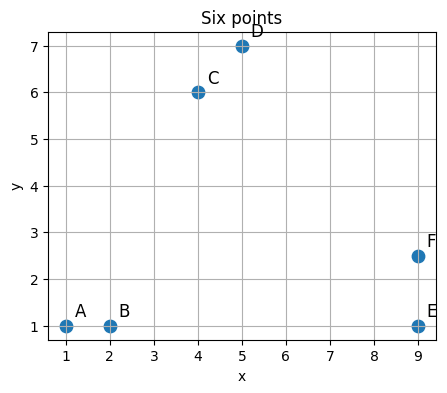

In [ ]:
names = ["A", "B", "C", "D", "E", "F"]
points = np.array([
    [1, 1],    # A
    [2, 1],    # B
    [4, 6],    # C
    [5, 7],    # D
    [9, 1],    # E
    [9, 2.5],  # F
])

plt.figure(figsize=(5, 4))
plt.scatter(points[:, 0], points[:, 1], s=80)
for i in range(len(names)):
    plt.text(points[i, 0] + 0.2, points[i, 1] + 0.2, names[i], fontsize=12)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Six points")
plt.grid(True)
plt.show()

Just by looking, we can guess there are three natural groups: {A, B}, {C, D} and {E, F}. Let us see if hierarchical clustering agrees.

## 4. Step 1: measure the distance between every pair of points

Hierarchical clustering needs to know how far apart the points are. The usual choice is the **Euclidean distance** (the straight-line distance):

$$d(p, q) = \sqrt{(x_p - x_q)^2 + (y_p - y_q)^2}$$

- `pdist` computes the distance between every pair of points.
- `squareform` arranges these distances into a square table (a **distance matrix**).

In [ ]:
distances = squareform(pdist(points, metric="euclidean"))

dist_table = pd.DataFrame(distances, index=names, columns=names).round(2)
dist_table

,A,B,C,D,E,F
A,0.00,1.00,5.83,7.21,8.00,8.14
B,1.00,0.00,5.39,6.71,7.00,7.16
C,5.83,5.39,0.00,1.41,7.07,6.10
D,7.21,6.71,1.41,0.00,7.21,6.02
E,8.00,7.00,7.07,7.21,0.00,1.50
F,8.14,7.16,6.10,6.02,1.50,0.00


**How to read the table:** the value in row A, column B is the distance between A and B. The diagonal is 0 (distance from a point to itself). The table is symmetric (A to B is the same as B to A).

The smallest non-zero value is **A-B = 1.00**, so A and B are the first pair to be merged.

## 5. Agglomerative clustering, step by step

The algorithm is simple:

1. Put every point in its own cluster (6 points = 6 clusters).
2. Find the two **closest** clusters.
3. Merge them into one cluster.
4. Repeat steps 2 and 3 until only one cluster is left.

With n points there are always **n - 1 merges** (here 5).

Step 2 needs a rule for "distance between two clusters" when a cluster has more than one point. This rule is called the **linkage criterion** (section 7). For now we use **single linkage**: the distance between two clusters is the distance between their **closest** pair of points.

The function `linkage` does all the merges for us and returns a table that records every merge.

In [ ]:
Z = linkage(points, method="single")

merge_table = pd.DataFrame(Z, columns=["cluster 1", "cluster 2", "distance", "points in new cluster"])
merge_table.index = ["merge 1", "merge 2", "merge 3", "merge 4", "merge 5"]
merge_table

,cluster 1,cluster 2,distance,points in new cluster
merge 1,0.0,1.0,1.000000,2.0
merge 2,2.0,3.0,1.414214,2.0
merge 3,4.0,5.0,1.500000,2.0
merge 4,6.0,7.0,5.385165,4.0
merge 5,8.0,9.0,6.020797,6.0


**How to read the merge table:**

- Original points are numbered 0 to 5 (A = 0, B = 1, C = 2, D = 3, E = 4, F = 5).
- Every new cluster gets the next number: the first new cluster is 6, the second is 7, and so on.

| Merge | What happened | New cluster |
|---|---|---|
| 1 | A (0) + B (1) at distance 1.00 | 6 = {A, B} |
| 2 | C (2) + D (3) at distance 1.41 | 7 = {C, D} |
| 3 | E (4) + F (5) at distance 1.50 | 8 = {E, F} |
| 4 | {A, B} (6) + {C, D} (7) at distance 5.39 | 9 = {A, B, C, D} |
| 5 | {A, B, C, D} (9) + {E, F} (8) at distance 6.02 | 10 = all six points |

Notice that merge 4 happens at distance 5.39. This is the distance from B to C, the closest pair between the two clusters (single linkage).

## 6. The dendrogram

A dendrogram draws the merge table as a tree.

- The **bottom** of the tree shows the individual points.
- Each **horizontal line** is a merge.
- The **height** of a horizontal line is the distance at which the merge happened.
- Long vertical lines mean the clusters were far apart before they were joined. This is a sign of well-separated groups.

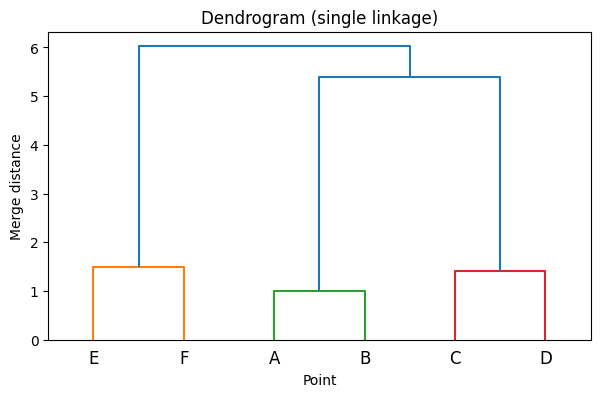

In [ ]:
plt.figure(figsize=(7, 4))
dendrogram(Z, labels=names)
plt.title("Dendrogram (single linkage)")
plt.xlabel("Point")
plt.ylabel("Merge distance")
plt.show()

### Cutting the dendrogram to get clusters

To get actual clusters, we **cut** the tree with a horizontal line. Every vertical line that the cut crosses becomes one cluster.

Where should we cut? The rule is: **cut in the largest vertical gap**, the longest stretch of height where no merges happen. A big gap means the clusters below it are far apart from each other, so they should stay separate.

To find the largest gap, list the merge heights from the merge table and subtract each one from the next.

In [ ]:
heights = Z[:, 2]           # column 2 of the merge table = merge heights
gaps = np.diff(heights)     # difference between each height and the next one

for i in range(len(gaps)):
    print("Gap between", round(heights[i], 2), "and", round(heights[i + 1], 2), "=", round(gaps[i], 2))

Gap between 1.0 and 1.41 = 0.41
Gap between 1.41 and 1.5 = 0.09
Gap between 1.5 and 5.39 = 3.89
Gap between 5.39 and 6.02 = 0.64


The largest gap is **3.89**, between heights 1.50 and 5.39. Any cut inside this gap (for example at height 3) crosses **3 vertical lines**, so the best choice is **3 clusters**.

For comparison, a cut at height 5.7 gives 2 clusters, but it sits in a small gap (only 0.64), so it is a weaker choice.

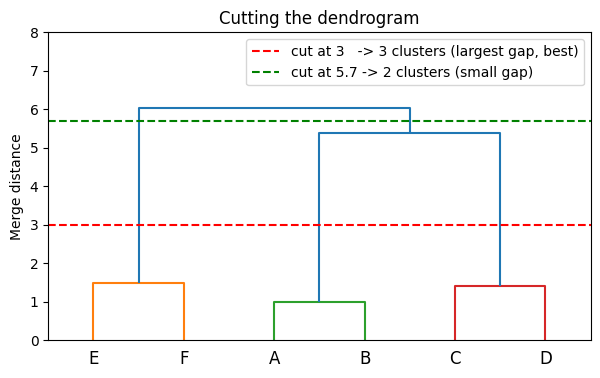

In [ ]:
plt.figure(figsize=(7, 4))
dendrogram(Z, labels=names)
plt.axhline(y=3, color="red", linestyle="--", label="cut at 3   -> 3 clusters (largest gap, best)")
plt.axhline(y=5.7, color="green", linestyle="--", label="cut at 5.7 -> 2 clusters (small gap)")
plt.title("Cutting the dendrogram")
plt.ylabel("Merge distance")
plt.ylim(0, 8)
plt.legend()
plt.show()

The function `fcluster` cuts the tree for us. There are two ways to use it:

- `criterion="distance"`: cut at a given **height** `t`
- `criterion="maxclust"`: ask for a given **number of clusters** `t`

In [ ]:
labels_by_height = fcluster(Z, t=3, criterion="distance")
labels_by_number = fcluster(Z, t=3, criterion="maxclust")

print("Points:                ", names)
print("Cut at height 3:       ", labels_by_height)
print("Ask for 3 clusters:    ", labels_by_number)

Points:                 ['A', 'B', 'C', 'D', 'E', 'F']
Cut at height 3:        [2 2 3 3 1 1]
Ask for 3 clusters:     [2 2 3 3 1 1]


Both ways give the same result: the three groups we guessed at the start, {A, B}, {C, D} and {E, F}. The largest-gap rule agrees with what we see in the scatter plot.

The cluster numbers themselves (1, 2, 3) have no meaning. Only which points share the same number matters.

## 7. Linkage criteria: how do we measure the distance between two clusters?

When a cluster has several points, there are different ways to define the distance to another cluster:

| Linkage | Distance between cluster P and cluster Q | Typical behaviour |
|---|---|---|
| **Single** | Distance of the **closest** pair (one point from P, one from Q) | Can follow long, curved shapes. Can also create long "chains" that join groups which should stay apart. |
| **Complete** | Distance of the **farthest** pair | Makes compact, round clusters of similar size. Sensitive to outliers. |
| **Average** | **Average** distance over all pairs | A balance between single and complete. |
| **Ward** | Merge the two clusters that cause the **smallest increase in total within-cluster variance** | Makes compact, balanced clusters (similar to K-Means). Works only with Euclidean distance. Often the default choice. |

Let us draw the dendrogram of our 6 points with each linkage.

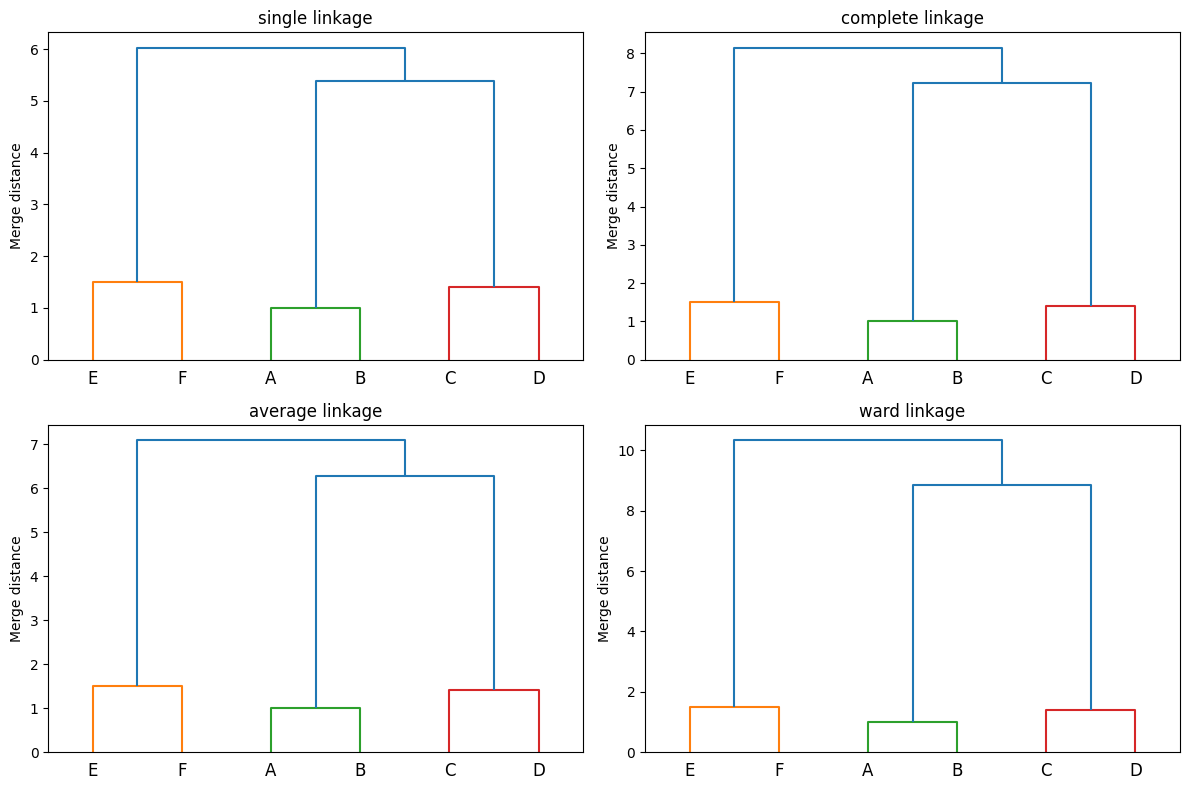

In [ ]:
methods = ["single", "complete", "average", "ward"]

plt.figure(figsize=(12, 8))
for i in range(4):
    plt.subplot(2, 2, i + 1)
    Z_method = linkage(points, method=methods[i])
    dendrogram(Z_method, labels=names)
    plt.title(methods[i] + " linkage")
    plt.ylabel("Merge distance")
plt.tight_layout()
plt.show()

**What to notice:**

- All four methods find the same three small groups here, because the data is very clean. In every dendrogram the largest gap is above these three groups, so every method suggests 3 clusters.
- The **heights** of the merges are different. For example, {A, B} and {C, D} join at 5.39 with single linkage (closest pair B-C) but at 7.21 with complete linkage (farthest pair A-D).
- Ward heights are larger because they measure the increase in variance, not a plain distance.

On real data with less clear groups, the methods can give very different clusters. We will see this next.

## 8. A larger example with scikit-learn

For bigger data we use `AgglomerativeClustering` from scikit-learn. It works like other sklearn models:

1. Create the model and choose `n_clusters` and `linkage`.
2. Call `fit_predict(X)` to get a cluster label for every point.

We create 30 points in 3 groups using `make_blobs`. `make_blobs` also returns the true group of every point, but in clustering we do not use it, so we store it in `_` (a name that means "not needed").

Shape of X: (30, 2)


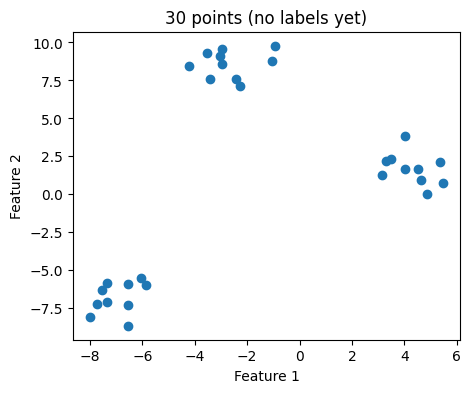

In [ ]:
X, _ = make_blobs(n_samples=30, centers=3, cluster_std=1.0, random_state=42)

print("Shape of X:", X.shape)   # 30 rows (points), 2 columns (features)

plt.figure(figsize=(5, 4))
plt.scatter(X[:, 0], X[:, 1])
plt.title("30 points (no labels yet)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

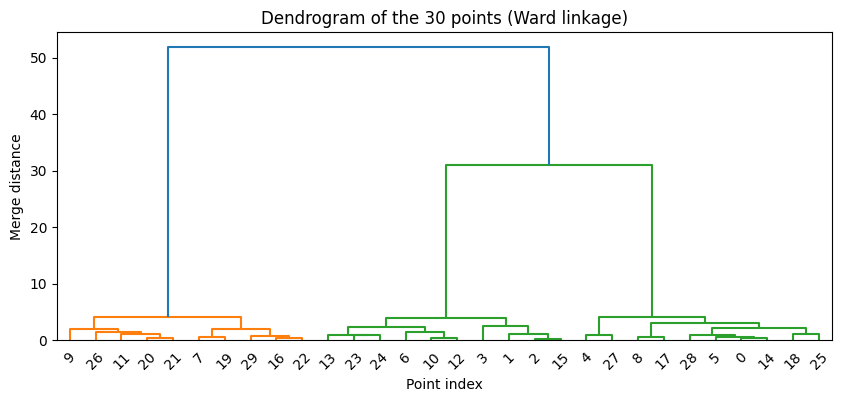

In [ ]:
# Dendrogram first, to decide how many clusters to use
Z_blobs = linkage(X, method="ward")

plt.figure(figsize=(10, 4))
dendrogram(Z_blobs)
plt.title("Dendrogram of the 30 points (Ward linkage)")
plt.xlabel("Point index")
plt.ylabel("Merge distance")
plt.show()

The dendrogram shows three long vertical branches before the last two merges. The largest gap suggests **3 clusters**. Now we use scikit-learn to get the labels.

Cluster labels: [1 2 2 2 1 1 2 0 1 0 2 0 2 2 1 2 0 1 1 0 0 0 0 2 2 1 0 1 1 0]


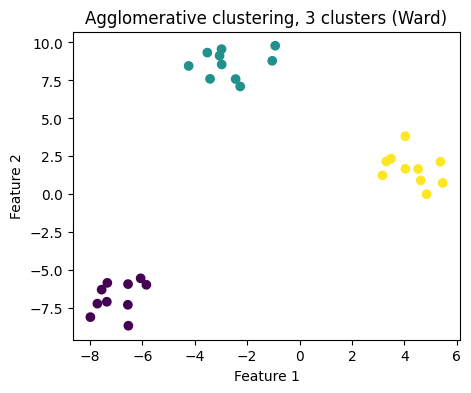

In [ ]:
model = AgglomerativeClustering(n_clusters=3, linkage="ward")
labels = model.fit_predict(X)

print("Cluster labels:", labels)

plt.figure(figsize=(5, 4))
plt.scatter(X[:, 0], X[:, 1], c=labels, cmap="viridis")
plt.title("Agglomerative clustering, 3 clusters (Ward)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

## 9. When does the linkage choice matter? The "two moons" example

`make_moons` creates two half-circle shapes. The groups are **not round**, so methods that like round clusters can fail.

We cluster the same data with all four linkages and compare the pictures. A good result colours each moon with one colour.

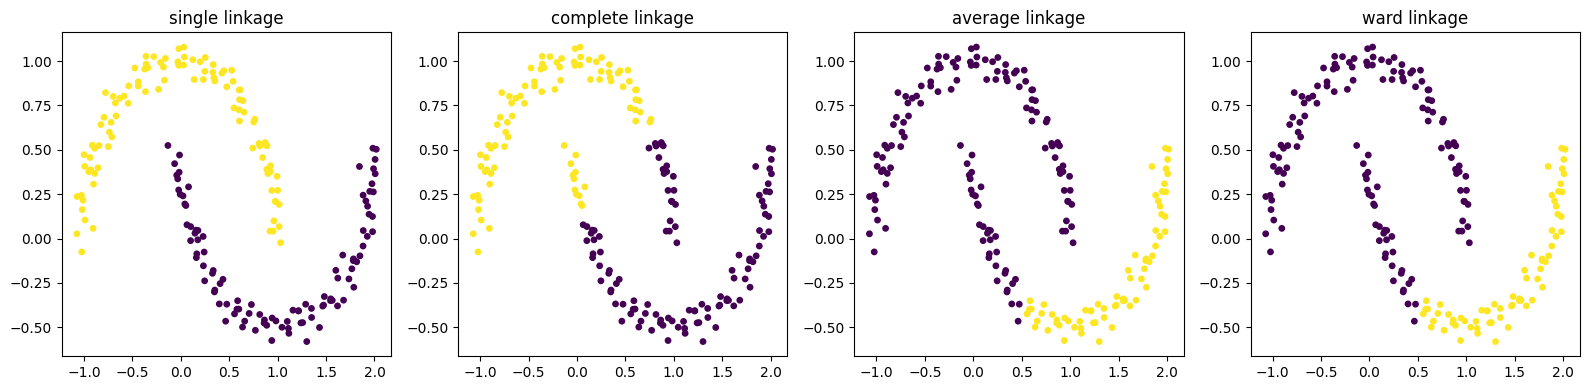

In [ ]:
X_moons, _ = make_moons(n_samples=200, noise=0.05, random_state=0)

methods = ["single", "complete", "average", "ward"]

plt.figure(figsize=(16, 4))
for i in range(4):
    model = AgglomerativeClustering(n_clusters=2, linkage=methods[i])
    labels_moons = model.fit_predict(X_moons)

    plt.subplot(1, 4, i + 1)
    plt.scatter(X_moons[:, 0], X_moons[:, 1], c=labels_moons, cmap="viridis", s=15)
    plt.title(methods[i] + " linkage")
plt.tight_layout()
plt.show()

**What to notice:**

- **Single linkage** follows the curved shapes and finds both moons correctly, because it only needs one close pair of points to keep joining neighbours.
- **Complete, average and Ward** prefer round, compact groups, so they cut the moons in the wrong place.

**Lesson:** there is no single best linkage. The right choice depends on the shape of your data. Ward is a good default for round groups. Single linkage is useful for long or curved groups, but it is easily confused by noise.

## 10. Evaluating hierarchical clustering

How do we know if a clustering is good? We use the **silhouette score**. It does not need any correct answers, only the data and the cluster labels.

For each point, the silhouette compares two distances:

- **a** = the average distance from the point to the other points in **its own** cluster (we want this small)
- **b** = the average distance from the point to the points in the **nearest other** cluster (we want this large)

$$s = \frac{b - a}{\max(a, b)}$$

The silhouette score of the whole clustering is the average of s over all points.

| Silhouette score | Meaning |
|---|---|
| Close to 1 | Points are close to their own cluster and far from others. Very good. |
| Around 0 | Points are on the border between two clusters. Clusters overlap. |
| Below 0 | Many points are probably in the wrong cluster. Bad. |

As a rough guide, a score above 0.5 is good. In scikit-learn: `silhouette_score(X, labels)`.

In [ ]:
methods = ["single", "complete", "average", "ward"]
results = []

for m in methods:
    model = AgglomerativeClustering(n_clusters=3, linkage=m)
    labels_m = model.fit_predict(X)
    score = silhouette_score(X, labels_m)
    results.append([m, score])

results_table = pd.DataFrame(results, columns=["linkage", "silhouette"])
results_table.round(3)

,linkage,silhouette
0,single,0.841
1,complete,0.841
2,average,0.841
3,ward,0.841


For this clean data with well-separated groups, all linkages find the same clusters, so they get the same score. On harder data the scores will differ, as you will see in the exercises.

### Choosing the number of clusters with the silhouette score

If we do not know how many clusters to use, we can try several values and pick the one with the **highest silhouette score**. This is a good check next to reading the dendrogram.

k = 2  silhouette = 0.694
k = 3  silhouette = 0.841
k = 4  silhouette = 0.684
k = 5  silhouette = 0.561
k = 6  silhouette = 0.404


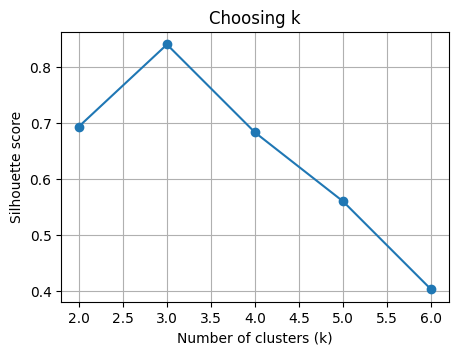

In [ ]:
k_values = [2, 3, 4, 5, 6]
scores = []

for k in k_values:
    model = AgglomerativeClustering(n_clusters=k, linkage="ward")
    labels_k = model.fit_predict(X)
    scores.append(silhouette_score(X, labels_k))
    print("k =", k, " silhouette =", round(scores[-1], 3))

plt.figure(figsize=(5, 3.5))
plt.plot(k_values, scores, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette score")
plt.title("Choosing k")
plt.grid(True)
plt.show()

The highest silhouette score is at **k = 3**, which agrees with the dendrogram.

## 11. Divisive clustering (top-down)

Divisive clustering works in the opposite direction:

1. Start with **all points in one cluster**.
2. Choose a cluster to split (here: the **biggest** cluster).
3. Split it into **two** parts.
4. Repeat steps 2 and 3 until you have the number of clusters you want.

How do we split a cluster into two? A simple and popular way is to run **K-Means with K = 2** on the points of that cluster. This version of divisive clustering is often called **bisecting K-Means**.

scikit-learn does not have a ready-made divisive hierarchical model, so we write a short function ourselves. Read the comments line by line.

In [ ]:
def divisive_clustering(X, n_clusters):
    # Step 1: every point starts in cluster 0
    labels = np.zeros(len(X), dtype=int)
    history = [labels.copy()]

    # We need (n_clusters - 1) splits
    for step in range(n_clusters - 1):
        # Step 2: find the biggest cluster
        sizes = np.bincount(labels)
        biggest = np.argmax(sizes)

        # Positions of the points that belong to the biggest cluster
        idx = np.where(labels == biggest)[0]

        # Step 3: split it into two with K-Means (K = 2)
        kmeans = KMeans(n_clusters=2, n_init=10, random_state=0)
        halves = kmeans.fit_predict(X[idx])

        # Points in half 1 get a new cluster number; half 0 keeps the old number
        new_label = labels.max() + 1
        labels[idx[halves == 1]] = new_label

        print("Split", step + 1, ": cluster", biggest, "(", len(idx), "points ) ->",
              "clusters", biggest, "and", new_label)
        history.append(labels.copy())

    return labels, history

Split 1 : cluster 0 ( 30 points ) -> clusters 0 and 1
Split 2 : cluster 1 ( 20 points ) -> clusters 1 and 2


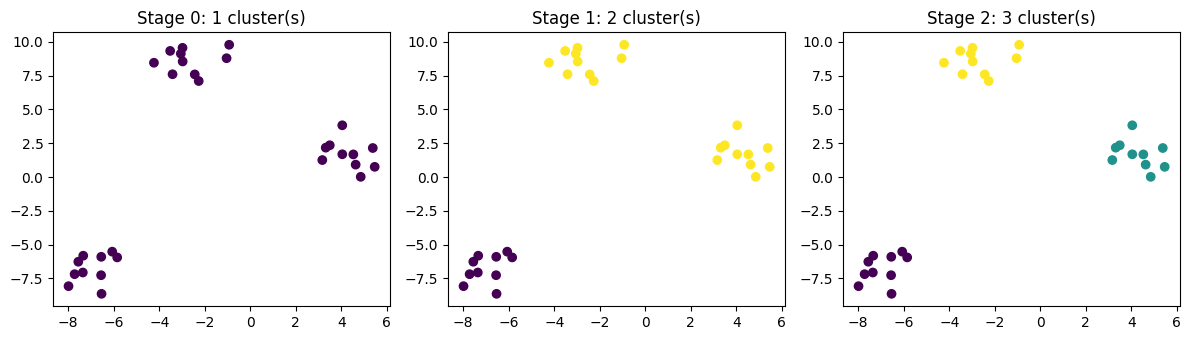

In [ ]:
div_labels, history = divisive_clustering(X, n_clusters=3)

# Plot every stage: 1 cluster -> 2 clusters -> 3 clusters
plt.figure(figsize=(12, 3.5))
for i in range(len(history)):
    plt.subplot(1, len(history), i + 1)
    plt.scatter(X[:, 0], X[:, 1], c=history[i], cmap="viridis")
    plt.title("Stage " + str(i) + ": " + str(i + 1) + " cluster(s)")
plt.tight_layout()
plt.show()

You can see the top-down idea: one cluster, then the first split, then the second split.

Let us compare the divisive result with the agglomerative (Ward) result using the silhouette score.

In [ ]:
agg_labels = AgglomerativeClustering(n_clusters=3, linkage="ward").fit_predict(X)

print("Divisive      silhouette:", round(silhouette_score(X, div_labels), 3))
print("Agglomerative silhouette:", round(silhouette_score(X, agg_labels), 3))

Divisive      silhouette: 0.841
Agglomerative silhouette: 0.841


### Agglomerative vs divisive

| | Agglomerative | Divisive |
|---|---|---|
| Direction | Bottom-up (merge) | Top-down (split) |
| Starts with | n clusters (one per point) | 1 cluster (all points) |
| Each step | Merge the two closest clusters | Split one cluster into two |
| Good at | Finding small, local groups accurately | Finding the big, main groups first |
| In libraries | Yes (`AgglomerativeClustering`, `scipy linkage`) | Less common; bisecting K-Means is a popular version |
| Cost | Slow for very large data (needs all pairwise distances) | Can be faster if you only need a few clusters |

## 12. Important: scale your features first

Hierarchical clustering is based on **distances**. If one feature has much larger numbers than another, it will control the distance and the other feature will be almost ignored.

Example: annual income (thousands of dollars, values like 30 to 90) and number of shop visits per month (values like 2 to 15). A difference of 10 in income looks as important as a difference of 10 visits, which is wrong.

`StandardScaler` fixes this. It changes every feature to have **mean 0 and standard deviation 1**, so all features count equally.

In [ ]:
data = np.array([
    [30, 2],
    [35, 14],
    [85, 3],
    [90, 15],
])
print("Before scaling:")
print(data)

scaler = StandardScaler()
data_scaled = scaler.fit_transform(data)

print("\nAfter scaling:")
print(data_scaled.round(2))

Before scaling:
[[30  2]
 [35 14]
 [85  3]
 [90 15]]

After scaling:
[[-1.09 -1.08]
 [-0.91  0.91]
 [ 0.91 -0.91]
 [ 1.09  1.08]]


After scaling, both columns are on the same scale. **Rule:** if your features use different units, scale them before clustering.

## 13. Summary of Session 1

- **Hierarchical clustering** builds a tree of clusters. You do not need to choose the number of clusters in advance.
- **Agglomerative** = bottom-up (merge). **Divisive** = top-down (split).
- The **linkage criterion** defines the distance between two clusters: single, complete, average or Ward.
- The **dendrogram** shows the tree. Cut it where the vertical gap is largest to choose the number of clusters.
- Evaluate with the **silhouette score** (from -1 to 1, higher is better). It also helps to choose the number of clusters.
- **Scale your features** before clustering.

### Key functions

| Task | Code |
|---|---|
| Distance matrix | `squareform(pdist(X))` |
| Build the tree | `Z = linkage(X, method="ward")` |
| Draw the dendrogram | `dendrogram(Z, labels=names)` |
| Cut into k clusters | `fcluster(Z, t=k, criterion="maxclust")` |
| sklearn model | `AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X)` |
| Silhouette score | `silhouette_score(X, labels)` |
| Scale features | `StandardScaler().fit_transform(X)` |

---
# SESSION 2: Graded Exercises

**Time:** about 30 minutes  **Total:** 100 marks

| Exercise | Topic | Marks |
|---|---|---|
| 1 | Distance matrix, dendrogram and cutting the tree | 30 |
| 2 | Comparing linkage criteria | 40 |
| 3 | Divisive vs agglomerative clustering | 30 |
| | **Total** | **100** |

**Instructions:**
- Work on your own.
- Replace every `___` (three underscores) with the correct code, then run the cell.
- Write your written answers in the markdown cells marked **Your answer**. Double-click the cell to edit it.
- Run the setup cell below first. All cells must run without errors before you submit.

In [25]:
# SETUP - run this cell first (not graded)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import pdist, squareform

from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.datasets import make_blobs
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

print("Setup complete")

Setup complete


## Exercise 1: Distance matrix, dendrogram and cutting the tree (30 marks)

The table below gives the marks of 8 students in Mathematics and Programming. Both subjects are out of 100, so no scaling is needed.

In [ ]:
students = ["Aziz", "Dilnoza", "Bekzod", "Malika", "Sardor", "Nodira", "Jasur", "Kamola"]
marks = np.array([
    [85, 80],   # Aziz
    [88, 84],   # Dilnoza
    [40, 35],   # Bekzod
    [45, 50],   # Malika
    [70, 30],   # Sardor
    [72, 28],   # Nodira
    [30, 38],   # Jasur
    [92, 89],   # Kamola
])
pd.DataFrame(marks, index=students, columns=["Mathematics", "Programming"])

,Mathematics,Programming
Aziz,85,80
Dilnoza,88,84
Bekzod,40,35
Malika,45,50
Sardor,70,30
Nodira,72,28
Jasur,30,38
Kamola,92,89


**1(a)** Compute the Euclidean distance matrix between all students and show it as a table rounded to 2 decimals. **(5 marks)**

In [46]:
distances1 = squareform(pdist(marks, metric="euclidean"))

dist_table1 = pd.DataFrame(distances1, index=students, columns=students).round(2)
dist_table1

,Aziz,Dilnoza,Bekzod,Malika,Sardor,Nodira,Jasur,Kamola
Aziz,0.00,5.00,63.64,50.00,52.20,53.60,69.20,11.40
Dilnoza,5.00,0.00,68.59,54.82,56.92,58.24,74.03,6.40
Bekzod,63.64,68.59,0.00,15.81,30.41,32.76,10.44,74.97
Malika,50.00,54.82,15.81,0.00,32.02,34.83,19.21,61.07
Sardor,52.20,56.92,30.41,32.02,0.00,2.83,40.79,62.97
Nodira,53.60,58.24,32.76,34.83,2.83,0.00,43.17,64.20
Jasur,69.20,74.03,10.44,19.21,40.79,43.17,0.00,80.28
Kamola,11.40,6.40,74.97,61.07,62.97,64.20,80.28,0.00


**1(b)** Build the tree with **complete** linkage and draw the dendrogram with the student names on the x-axis. Give the plot a title. **(10 marks)**

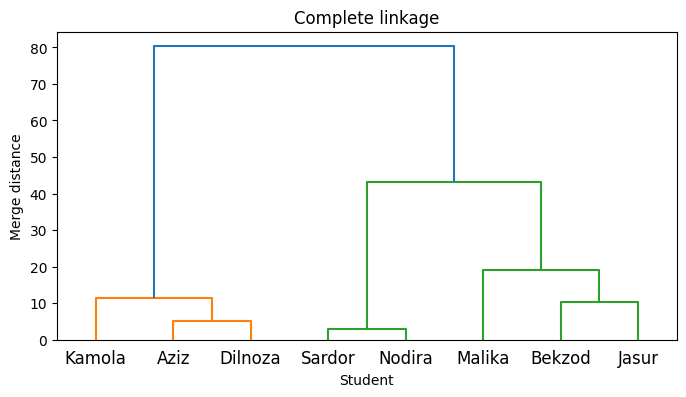

In [29]:
Z1 = linkage(marks, method="complete")

plt.figure(figsize=(8, 4))
dendrogram(Z1, labels=students)
plt.title("Complete linkage")
plt.xlabel("Student")
plt.ylabel("Merge distance")
plt.show()

**1(c)** Cut the tree into **3 clusters** using `fcluster` and print each student with their cluster number. **(10 marks)**

In [32]:
clusters1 = fcluster(Z1, t=3, criterion="maxclust")

for i in range(len(students)):
    print(students[i], "-> cluster", clusters1[i])

Aziz -> cluster 1
Dilnoza -> cluster 1
Bekzod -> cluster 3
Malika -> cluster 3
Sardor -> cluster 2
Nodira -> cluster 2
Jasur -> cluster 3
Kamola -> cluster 1


**1(d)** Written answer: Which two students were merged **first**, and why? Use your distance table to support your answer. **(5 marks)**

**Your answer:**

**Sardor** and **Nodira** were merged first.

**Why?** According to the Euclidean distance table, their p distance is **2.83**, which is the smallest non-zero value in the entire matrix. Hierarchical agglomerative clustering always begins by merging the two most similar  individual points.

## Exercise 2: Comparing linkage criteria (40 marks)

A shop has data on 100 customers: **annual income** (in thousands of dollars) and **number of visits per month**. Run the cell below to create the data.

In [33]:
rng = np.random.default_rng(7)
income = np.concatenate([rng.normal(40, 12, 25), rng.normal(45, 12, 25),
                         rng.normal(95, 12, 25), rng.normal(100, 12, 25)])
visits = np.concatenate([rng.normal(6, 2.5, 25), rng.normal(16, 2.5, 25),
                         rng.normal(7, 2.5, 25), rng.normal(17, 2.5, 25)])
customers = np.column_stack([income, visits])

print("Shape:", customers.shape)
pd.DataFrame(customers, columns=["Income", "Visits"]).describe().round(2)

Shape: (100, 2)


,Income,Visits
count,100.00,100.00
mean,67.92,11.27
std,31.03,5.85
min,14.80,1.01
25%,39.55,5.78
50%,70.05,11.37
75%,96.64,16.63
max,118.28,20.79


**2(a)** The two features use very different units. Scale the data with `StandardScaler`. **(5 marks)**

In [35]:
scaler = StandardScaler()
customers_scaled = scaler.fit_transform(customers)

print(customers_scaled[:5].round(2))

[[-0.9  -1.04]
 [-0.79 -1.29]
 [-1.01 -0.84]
 [-1.25  0.06]
 [-1.08 -1.26]]


**2(b)** For each linkage (`single`, `complete`, `average`, `ward`), cluster the **scaled** data into **4 clusters** with `AgglomerativeClustering` and compute the silhouette score. Store the results in a table. **(15 marks)**

In [36]:
methods = ["single", "complete", "average", "ward"]
results2 = []

for m in methods:
    model = AgglomerativeClustering(n_clusters=4, linkage=m)
    labels2 = model.fit_predict(customers_scaled)
    score = silhouette_score(customers_scaled, labels2)
    results2.append([m, score])

table2 = pd.DataFrame(results2, columns=["linkage", "silhouette"]).round(3)
table2

,linkage,silhouette
0,single,0.291
1,complete,0.600
2,average,0.607
3,ward,0.619


**2(c)** Choose the linkage with the **highest** silhouette score. Cluster the scaled data again with that linkage and draw a scatter plot of the **original** (unscaled) data coloured by cluster. Label both axes and add a title. **(10 marks)**

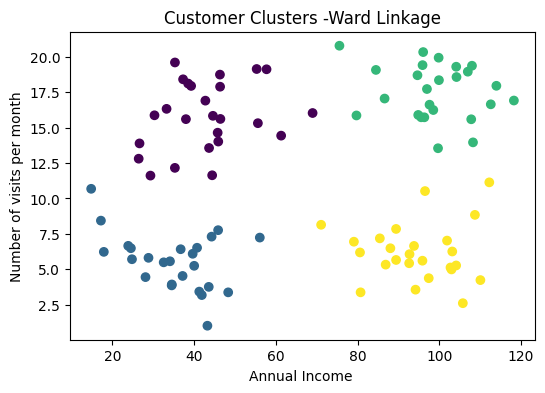

In [40]:
best_method = "ward"

best_labels = AgglomerativeClustering(n_clusters=4, linkage=best_method).fit_predict(customers_scaled)

plt.figure(figsize=(6, 4))
plt.scatter(customers[:, 0], customers[:, 1], c=best_labels, cmap="viridis")
plt.xlabel("Annual Income ")
plt.ylabel("Number of visits per month")
plt.title("Customer Clusters -Ward Linkage")
plt.show()

**2(d)** Written answer: **(10 marks)**
1. Which linkage gave the best silhouette score, and which gave the worst? (4 marks)
2. Give one reason why the worst linkage performed badly on this data. (3 marks)
3. Why did we scale the data before clustering? (3 marks)

**Your answer:**

1. Ward linkage was the best score: 0.619 and single linkage was the worst score: 0.291


2. Single linkage performs poorly because of the chaining effect. It wants to merge  groups together if there are any close points in between, creating one big cluster and leaving single points alone.

3. We scaled the data so that both features count equally. Without scaling, the feature with larger numbers (Income) would dominate the distance calculations and completely ignore the smaller feature (Visits).

## Exercise 3: Divisive vs agglomerative clustering (30 marks)

Run the cell below. It creates 150 points and defines the `divisive_clustering` function from Session 1.

In [37]:
X3, _ = make_blobs(n_samples=150, centers=3, cluster_std=1.5, random_state=7)

def divisive_clustering(X, n_clusters):
    labels = np.zeros(len(X), dtype=int)
    for step in range(n_clusters - 1):
        sizes = np.bincount(labels)
        biggest = np.argmax(sizes)
        idx = np.where(labels == biggest)[0]
        kmeans = KMeans(n_clusters=2, n_init=10, random_state=0)
        halves = kmeans.fit_predict(X[idx])
        labels[idx[halves == 1]] = labels.max() + 1
    return labels

print("Data shape:", X3.shape)

Data shape: (150, 2)


**3(a)** Use `divisive_clustering` to split `X3` into **3 clusters**. Then use `AgglomerativeClustering` with **Ward** linkage to also get **3 clusters**. **(10 marks)**

In [41]:
div3 = divisive_clustering(X3, n_clusters=3)

agg3 = AgglomerativeClustering(n_clusters=3, linkage="ward").fit_predict(X3)

print("Divisive labels (first 10):     ", div3[:10])
print("Agglomerative labels (first 10):", agg3[:10])

Divisive labels (first 10):      [0 2 0 2 1 2 0 1 2 0]
Agglomerative labels (first 10): [1 2 1 2 0 2 1 0 2 1]


**3(b)** Draw the two results side by side (two subplots), each with a title. **(5 marks)**

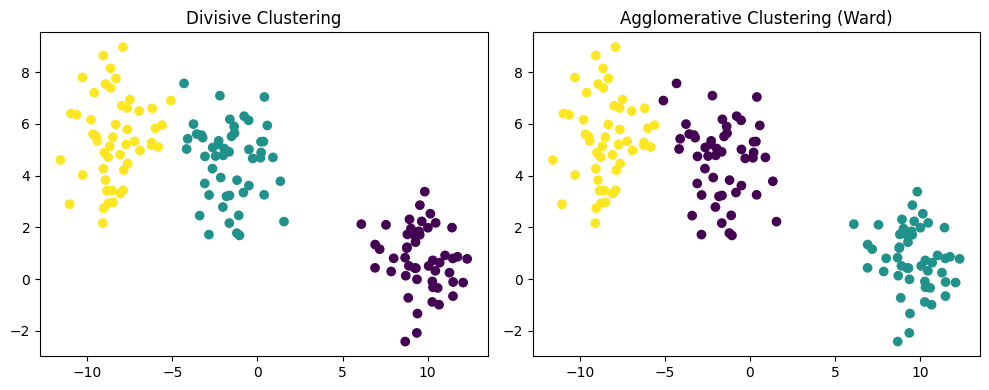

In [43]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.scatter(X3[:, 0], X3[:, 1], c=div3, cmap="viridis")
plt.title("Divisive Clustering")

plt.subplot(1, 2, 2)
plt.scatter(X3[:, 0], X3[:, 1], c=agg3, cmap="viridis")
plt.title("Agglomerative Clustering (Ward)")

plt.tight_layout()
plt.show()

**3(c)** Compute the **silhouette score** for both methods, print them, and print which method has the higher score. **(10 marks)**

In [44]:
score_div = silhouette_score(X3, div3)
score_agg = silhouette_score(X3, agg3)

print("Divisive      silhouette:", round(score_div, 3))
print("Agglomerative silhouette:", round(score_agg, 3))

if score_div > score_agg:
    print("Divisive has the higher silhouette score")
else:
    print("Agglomerative has the higher (or equal) silhouette score")

Divisive      silhouette: 0.671
Agglomerative silhouette: 0.67
Divisive has the higher silhouette score


**3(d)** Written answer: Explain in 2 to 3 sentences the main difference between the agglomerative and the divisive approach. **(5 marks)**

**Your answer:**

The main difference is that **agglomerative clustering** is a **bottom-up** approach, starting with each point as its own cluster and merging the closest pairs iteratively, whereas **divisive clustering** is a **top-down** approach, beginning with all points in a single cluster and iteratively splitting them. This means agglomerative clustering focuses on finding smaller, local groupings first, while divisive clustering is better at capturing the overarching global structure of the data.